# Object detection

Phân loại ảnh chỉ trả lời ảnh có chai nước hay không. Object detection trả về danh sách vật thể, mỗi vật có lớp, khung bao (box) và điểm tin cậy (score), nên biết được có mấy chai và mỗi chai ở đâu. Bài này học cách đo độ trùng giữa hai box (IoU), cách bỏ các box trùng nhau cho cùng một vật (NMS), và cách chấm model detection bằng mAP.

> **Mục tiêu**
>
> - Đổi giữa các định dạng box.
> - Tính IoU và cài NMS.
> - Tính precision–recall và AP.
> - Phân biệt các loại detector; dùng detector có sẵn và chọn ngưỡng.

## Một ảnh cho một danh sách dài ngắn khác nhau

Detection khác classification ở chỗ số vật thể không cố định. Ta có thể biểu diễn một ảnh bằng `boxes: (M,4)`, `labels: (M,)`, `scores: (M,)`. $M$ là số dự đoán của ảnh đó, không phải batch size. Ảnh không có vật nào cho `boxes` shape `(0,4)`. Vì $M$ khác nhau giữa các ảnh, một batch ảnh đi kèm một danh sách các bộ ba như vậy chứ không phải một tensor chung.

Nói gọn, phân loại trả một nhãn cho cả ảnh; phát hiện vật thể (object detection) trả mỗi vật một khung chữ nhật bao quanh (bounding box) kèm nhãn và độ tin cậy, nên khi gán nhãn dữ liệu, mỗi vật cần một box và một lớp. Nhiều hệ thống ghép hai bước: phát hiện vùng trước, như biển số hay khuôn mặt, rồi mới đọc ký tự hoặc phân loại vùng đó.

Box có ba cách ghi thường gặp, gốc $(0, 0)$ ở góc trên trái:

- `xyxy`: hai góc $(x_1,y_1),(x_2,y_2)$ theo pixel. TorchVision dùng cách này.
- `xywh`: góc trên trái, rồi rộng và cao, theo pixel. File COCO JSON dùng cách này.
- `cxcywh` chuẩn hóa: tâm $(c_x,c_y)$ cùng rộng, cao, cả bốn số chia cho kích thước ảnh nên nằm trong 0–1. Nhãn kiểu YOLO dùng cách này.

Không có một quy ước chung cho mọi thư viện, nên format box là điều đầu tiên cần đọc trong đề. Box `xyxy` $(10, 20, 50, 80)$ có tâm $(30, 50)$, rộng 40, cao 60; trong `cxcywh` chuẩn hóa, $c_x = 0.5$ nghĩa là tâm nằm giữa ảnh theo chiều ngang. Thu ảnh $800 \times 600$ về $400 \times 300$ thì mọi tọa độ box chia 2.



Ta thống nhất tọa độ biên liên tục, diện tích $(x_2-x_1)(y_2-y_1)$. Không cộng 1 như một số quy ước hộp điểm ảnh đóng. Ảnh có trục $x$ sang phải, $y$ xuống dưới; khi resize hoặc letterbox, box cần chuyển về hệ tọa độ ảnh gốc trước khi xuất.

**Hỏi nhanh.** Ảnh rộng 640, cao 480. Nhãn YOLO ghi `cxcywh = (0.5, 0.5, 0.25, 0.5)`. Đổi sang `xyxy` theo pixel thì box là gì?

- A. `[320, 240, 480, 480]`
- B. `[160, 0, 480, 480]`
- C. `[240, 120, 400, 360]`
- D. `[180, 160, 300, 480]`

<details><summary>Đáp án</summary>

C. `[240, 120, 400, 360]`

Tâm là $(0.5\cdot 640,\ 0.5\cdot 480) = (320, 240)$. Box rộng $0.25\cdot 640 = 160$ và cao $0.5\cdot 480 = 240$. Vậy $x$ chạy từ $320 - 80$ tới $320 + 80$, còn $y$ chạy từ $240 - 120$ tới $240 + 120$. `[320, 240, 480, 480]` coi tâm là góc trên trái. `[160, 0, 480, 480]` trừ cả chiều rộng và chiều cao thay vì một nửa. `[180, 160, 300, 480]` nhân tọa độ $x$ với chiều cao ảnh và $y$ với chiều rộng.

</details>

## IoU: đo mức chồng lên nhau

Intersection over union (IoU) lấy diện tích giao chia diện tích hợp:

$$\operatorname{IoU}(A,B)=\frac{|A\cap B|}{|A|+|B|-|A\cap B|}.$$

IoU bằng 1 khi hai box trùng nhau, 0 khi không có giao có diện tích dương. Nó so vị trí và kích thước, không so lớp; box đúng vị trí mà lớp sai vẫn có thể là dự đoán sai.

### Ví dụ tính tay

$A=[0,0,4,4]$, $B=[1,1,5,5]$. Giao có góc $(1,1)$ và $(4,4)$ nên diện tích $3\cdot3=9$. Hai box đều có diện tích 16, hợp là $16+16-9=23$, IoU $9/23\approx0.3913$. Nếu metric yêu cầu IoU $\ge0.5$, box B chưa khớp A.

Hai box $4 \times 4$ lệch ngang 2 có giao 8, hợp 24, IoU $1/3$; $(0,0,4,4)$ với $(2,2,6,6)$ chỉ giao 4, IoU $4/28 \approx 0.14$.

IoU bằng 0 với mọi cặp không giao nên không cho biết hai box xa hay gần. GIoU trừ thêm phần thừa của hộp nhỏ nhất $C$ chứa cả hai, $\mathrm{GIoU} = \mathrm{IoU} - (|C| - |A \cup B|)/|C|$: $A = (0,0,1,1)$, $B = (2,0,3,1)$ có $C$ rộng 3 nên GIoU là $0 - (3 - 2)/3 = -1/3$.

Ta viết hàm nhỏ có kiểm box hợp lệ. Chạm cạnh không tạo diện tích, nên bề rộng/chiều cao giao dùng `max(0, ...)`.

In [ ]:
import numpy as np

def box_iou(a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    assert a[2] > a[0] and a[3] > a[1]
    assert b[2] > b[0] and b[3] > b[1]
    left = max(a[0], b[0])
    top = max(a[1], b[1])
    right = min(a[2], b[2])
    bottom = min(a[3], b[3])
    intersection = max(0, right - left) * max(0, bottom - top)
    area_a = (a[2] - a[0]) * (a[3] - a[1])
    area_b = (b[2] - b[0]) * (b[3] - b[1])
    return intersection / (area_a + area_b - intersection)

print(round(box_iou([0, 0, 4, 4], [1, 1, 5, 5]), 4))
print(box_iou([0, 0, 4, 4], [4, 0, 8, 4]))

0.3913
0.0


Hai giá trị đối chiếu tính tay và trường hợp chạm biên. Nếu code cho IoU âm, thường ta đã quên chặn diện tích giao hoặc hiểu sai format.



**Hỏi nhanh.** Box ground truth $40\times 40$, dự đoán cùng cỡ lệch ngang 1 pixel thì IoU khoảng 0.95. Nếu box ground truth chỉ $4\times 4$ và dự đoán cùng cỡ cũng lệch ngang đúng 1 pixel, IoU bằng bao nhiêu?

- A. $0.375$
- B. $0.6$
- C. $0.75$
- D. $0.95$

<details><summary>Đáp án</summary>

B. $0.6$

Phần giao là $3\cdot 4 = 12$, phần hợp là $16 + 16 - 12 = 20$, nên IoU bằng 0.6. Cùng lệch một pixel, nhưng vật nhỏ mất IoU nhiều hơn hẳn. Vì vậy AP của vật nhỏ thường thấp nhất, và ngưỡng IoU càng cao càng khắt khe với chúng. 0.95 là nghĩ IoU không phụ thuộc kích thước. 0.75 là chia phần giao cho diện tích một box. 0.375 là chia cho tổng hai diện tích mà quên trừ phần giao.

</details>



## NMS: bỏ những box trùng dự đoán

Nhiều detector sinh nhiều ứng viên quanh một vật thể. Non-maximum suppression (NMS) là một thuật toán tham lam:

1. Giữ box có score cao nhất.
2. Bỏ mọi box còn lại chồng lên nó với IoU vượt ngưỡng.
3. Lặp với phần còn lại.

Trong ví dụ một lớp, ba ứng viên có score 0.9, 0.8, 0.7. Box 0 và 1 chồng nhiều; box 2 ở xa. Ta kiểm với thư viện để xác nhận quy ước “lớn hơn threshold”.

In [ ]:
boxes = np.array([[0, 0, 4, 4],
                  [0.5, 0.5, 4.5, 4.5],
                  [6, 0, 10, 4]], dtype=float)
scores = np.array([0.9, 0.8, 0.7])

def nms_one_class(boxes, scores, threshold):
    remaining = list(np.argsort(-scores, kind="stable"))
    kept = []
    while remaining:
        best = remaining.pop(0)
        kept.append(int(best))
        remaining = [index for index in remaining
                     if box_iou(boxes[best], boxes[index]) <= threshold]
    return kept

kept = nms_one_class(boxes, scores, threshold=0.5)
print("kept:", kept)
import torch
from torchvision.ops import nms
library_kept = nms(torch.tensor(boxes, dtype=torch.float32),
                   torch.tensor(scores, dtype=torch.float32), 0.5)
print("library:", library_kept.tolist())

kept: [0, 2]
library: [0, 2]


Cả hai giữ 0 và 2. Box 1 chồng box 0 với IoU $3.5^2/(32-3.5^2)\approx0.62>0.5$ nên bị loại; box 2 không chạm box 0 nên ở lại.



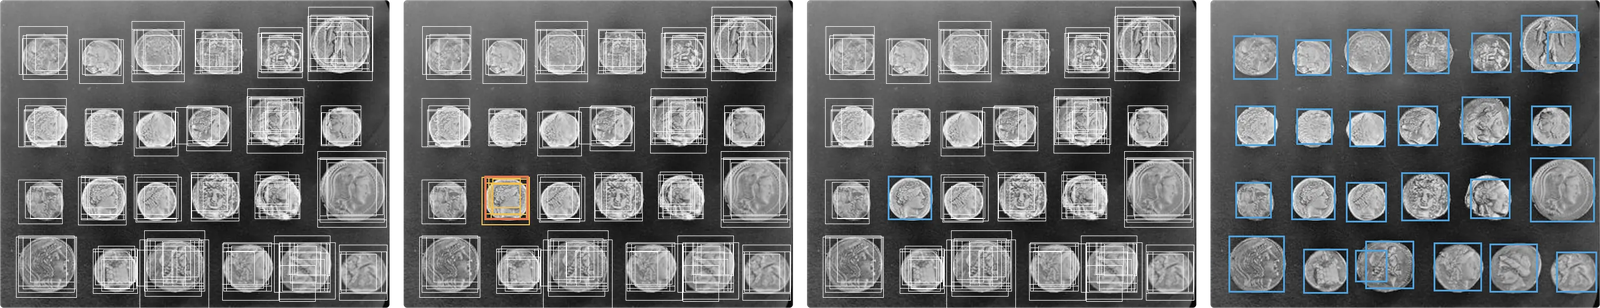

NMS giả định các box chồng mạnh cùng lớp là ứng viên lặp của cùng một vật. Trong đám đông, hai vật thật có thể chồng box: hai người đứng sát nhau có box IoU 0.6 thì NMS ngưỡng 0.5 sẽ xóa một người. Ngưỡng NMS thấp dễ mất recall; ngưỡng cao lại để lọt box trùng.

Ngưỡng score và ngưỡng IoU của NMS là hai nút khác nhau: một loại bỏ ứng viên thiếu tự tin, một loại bỏ ứng viên trùng nhau. Vòng lặp trên tốn tới $O(n^2)$ phép tính IoU với $n$ ứng viên, nên ảnh đông vật chạy chậm hơn rõ rệt.

**Hỏi nhanh.** Hai người đứng sát nhau, box của họ có IoU 0.6. Đặt `iou_threshold` của NMS bằng 0.4 thì có rủi ro gì?

- A. Box có score thấp hơn bị xóa, dù đó là một người thật
- B. Hai box chỉ đổi thứ tự, NMS không xóa box nào
- C. Chỉ box có score dưới 0.4 bị loại, IoU không được dùng
- D. Score của box được giữ tăng lên để bù cho box bị xóa

<details><summary>Đáp án</summary>

A. Box có score thấp hơn bị xóa, dù đó là một người thật

NMS chỉ nhìn IoU giữa các box. $0.6 > 0.4$, nên box có score thấp hơn bị loại và recall giảm. Phương án “score dưới 0.4” nhầm ngưỡng score với ngưỡng IoU. NMS xóa box chứ không chỉ sắp xếp lại, và không sửa score của box được giữ.

</details>

NMS chuẩn làm riêng từng lớp. Người ngồi trên xe đạp cho hai box chồng nhiều nhưng khác lớp; trộn lớp thì box xe đạp bị xóa. `batched_nms` nhận thêm nhãn và chỉ so các box cùng lớp.

In [ ]:
from torchvision.ops import batched_nms
rider = torch.tensor([[0, 0, 4, 8], [0, 2, 4, 9]], dtype=torch.float32)
rider_scores = torch.tensor([0.9, 0.8])
rider_labels = torch.tensor([0, 1])  # 0 = người, 1 = xe đạp
print("IoU:", round(box_iou(rider[0], rider[1]), 4))
print("trộn lớp:", nms(rider, rider_scores, 0.5).tolist())
print("theo lớp:", batched_nms(rider, rider_scores, rider_labels, 0.5).tolist())

IoU: 0.6667
trộn lớp: [0]
theo lớp: [0, 1]




Có thể cài NMS theo lớp bằng đúng một lần gọi `nms`: cộng vào cả bốn tọa độ của mọi box lớp $c$ cùng một lượng $c\cdot(m+1)$, với $m$ là tọa độ lớn nhất trong batch. TorchVision dùng mẹo này khi số box không quá lớn. Detector kiểu DETR (mục “Các họ detector”) không cần NMS; không áp thêm NMS chỉ theo thói quen.

**Hỏi nhanh.** Ta cộng vào tọa độ mỗi box một offset $c\cdot(m + 1)$ theo lớp $c$ của nó, rồi gọi `nms` một lần. Vì sao kết quả giống hệt chạy NMS riêng cho từng lớp?

- A. Vì score của lớp sau bị giảm, nên các lớp được xét lần lượt
- B. Vì box lớp sau bị phóng to, nên box lớp trước không loại được
- C. Vì mọi cặp box giữ nguyên IoU, chỉ thứ tự sắp xếp thay đổi
- D. Vì box khác lớp bị tách rời, IoU bằng 0, còn box cùng lớp giữ nguyên IoU

<details><summary>Đáp án</summary>

D. Vì box khác lớp bị tách rời, IoU bằng 0, còn box cùng lớp giữ nguyên IoU

Tịnh tiến hai box cùng một lượng thì IoU không đổi, nên các cặp cùng lớp được xử lý như cũ. Box lớp $c$ nằm trong đoạn $[c(m + 1),\ c(m + 1) + m]$. Đoạn của các lớp khác nhau rời nhau, nên IoU giữa chúng bằng 0 và không box nào loại box khác lớp. Offset cộng vào tọa độ chứ không vào score, và không đổi kích thước box. Nếu mọi cặp giữ nguyên IoU thì người và xe đạp vẫn loại nhau như ở dòng “trộn lớp”.

</details>

## Ghép đúng một lần trước khi tính điểm

Giả sử ảnh có hai chai thật. Dự đoán theo score giảm dần là chai A đúng, chai A lần nữa, chai B đúng. Ground truth A chỉ được ghép một lần, nên chuỗi là TP, FP, TP. Nếu tính cả hai box A là đúng, ta sẽ thưởng việc khoanh trùng. Box đúng lớp nhưng IoU chỉ 0.4 khi ngưỡng là 0.5 cũng là FP, và vật thật ấy thành FN nếu không có box nào khác khớp.

Sau mỗi dự đoán, precision là số TP chia số dự đoán đã giữ; recall là số TP chia tổng ground truth. Với chuỗi trên:

| Đã đọc | TP tích lũy | Precision | Recall |
|---|---:|---:|---:|
| 1 | 1 | 1 | 1/2 |
| 2 | 1 | 1/2 | 1/2 |
| 3 | 2 | 2/3 | 1 |

Code dưới ghép cho một ảnh, một lớp: duyệt dự đoán theo score giảm dần, mỗi dự đoán lấy ground truth **chưa ghép** có IoU cao nhất; đạt ngưỡng 0.5 thì là TP, không thì FP. Scorer COCO theo cùng quy tắc và có thêm vùng crowd: dự đoán rơi vào đó được bỏ qua, không tính FP.

In [ ]:
ground_truth = np.array([[0, 0, 4, 4], [6, 0, 10, 4]], dtype=float)
ranked_boxes = ground_truth[[0, 0, 1]]
matched = set()
true_positive = []
for predicted in ranked_boxes:
    available = [j for j in range(len(ground_truth)) if j not in matched]
    best = max(available, key=lambda j: box_iou(predicted, ground_truth[j]),
               default=None)
    correct = best is not None and box_iou(predicted, ground_truth[best]) >= 0.5
    true_positive.append(int(correct))
    if correct:
        matched.add(best)

tp = np.cumsum(true_positive)
precision = tp / np.arange(1, len(tp) + 1)
recall = tp / len(ground_truth)
print("TP flags:", true_positive)
print("precision:", precision.round(4).tolist())
print("recall:", recall.tolist())

TP flags: [1, 0, 1]
precision: [1.0, 0.5, 0.6667]
recall: [0.5, 0.5, 1.0]


Recall đứng yên ở box trùng, precision giảm. Nếu đếm chai bằng số box giữ lại, box trùng này cũng biến 2 chai thành 3: lỗi ghép và lỗi đếm có cùng gốc.



**Hỏi nhanh.** Ảnh có một chai A, ngưỡng IoU là 0.5. Dự đoán P có score 0.9 và IoU 0.55 với A. Dự đoán Q có score 0.6 và IoU 0.9 với A. Scorer ghép hai dự đoán này thế nào?

- A. P là FP, Q là TP, vì Q khớp A chặt hơn
- B. Cả P và Q là TP, vì cùng vượt ngưỡng 0.5
- C. P là TP, Q là FP, vì P được xét trước
- D. Cả P và Q là FP, vì hai box chồng lên nhau

<details><summary>Đáp án</summary>

C. P là TP, Q là FP, vì P được xét trước

Các dự đoán được duyệt theo score. P đến trước, đạt ngưỡng, và lấy A. Khi Q đến thì A đã có chủ, nên Q là FP dù khớp tốt hơn. Vì vậy detector có lợi khi score phản ánh cả chất lượng định vị. Cho cả hai là TP tức dùng một ground truth hai lần. Hai box chồng nhau không tự thành FP, vì xử lý chồng lấn là việc của NMS trước khi chấm.

</details>

## AP và mAP nói gì?

Average precision (AP) tóm tắt đường precision–recall (bài 1.5) khi thay đổi ngưỡng score. Trong cách all-points, ta lấy đường bao precision $p_{\mathrm{interp}}(r)=\max_{r'\ge r}p(r')$, rồi cộng diện tích các đoạn recall tăng. Ví dụ tính tay có AP $0.5\cdot1+0.5\cdot(2/3)=5/6$.

In [ ]:
def ap_all_points(precision, recall):
    p = np.r_[0.0, precision, 0.0]
    r = np.r_[0.0, recall, 1.0]
    envelope = np.maximum.accumulate(p[::-1])[::-1]
    return float(np.sum((r[1:] - r[:-1]) * envelope[1:]))

print("AP vi du:", round(ap_all_points(precision, recall), 4))
print("mAP vi du:", round(np.mean([5 / 6, 1 / 2]), 4))

AP vi du: 0.8333
mAP vi du: 0.6667


mAP là trung bình AP qua các lớp; dòng thứ hai lấy trung bình cho hai lớp có AP $5/6$ và $1/2$. Con số này còn phụ thuộc ngưỡng IoU dùng khi ghép:

- AP50 (kiểu PASCAL VOC) chỉ cần IoU $\ge0.5$.
- COCO lấy trung bình qua 10 ngưỡng IoU $0.50, 0.55, \dots, 0.95$.
 [Mã COCOeval](https://github.com/cocodataset/cocoapi/blob/master/PythonAPI/pycocotools/cocoeval.py) là nguồn để kiểm định nghĩa. “mAP” thiếu ngưỡng và quy ước chưa đủ để so điểm.



**Hỏi nhanh.** Có hai vật thật. Chuỗi dự đoán TP, FP, TP cho AP bằng $5/6$. Thêm một dự đoán sai, tức một FP, có score thấp hơn mọi dự đoán khác. AP all-points mới bằng bao nhiêu?

- A. $1/2$
- B. $2/3$
- C. $3/4$
- D. $5/6$

<details><summary>Đáp án</summary>

D. $5/6$

Recall đạt 1 ở TP thứ hai. Envelope tại recall 1 lấy precision lớn nhất trong các điểm có recall từ 1 trở lên, tức $\max(2/3,\ 1/2) = 2/3$, nên diện tích không đổi. FP xếp sau TP cuối cùng không làm giảm AP. $3/4$ dùng precision $1/2$ của điểm cuối thay cho envelope. $2/3$ là trung bình precision của bốn dự đoán, không phải AP. $1/2$ là precision cuối, $2/4$.

</details>

## Các họ detector

Mọi detector đều biến ảnh thành danh sách box; các họ khác nhau ở cách sinh ứng viên.

Cách cổ điển hơn nữa là trượt một cửa sổ khắp ảnh ở nhiều cỡ và chạy bộ phân loại ở mỗi vị trí: hàng vạn lần chạy cho một ảnh. Các họ dưới đây tìm cách tránh chi phí ấy.

**Hai giai đoạn: đề xuất rồi phân loại.** R-CNN (2014) lấy khoảng 2000 vùng đề xuất từ một thuật toán ngoài, cắt và resize từng vùng rồi chạy CNN riêng cho mỗi vùng để phân loại. Fast R-CNN chạy CNN một lần trên cả ảnh, rồi cắt đặc trưng của từng vùng ngay trên feature map.

Faster R-CNN thay thuật toán ngoài bằng region proposal network (RPN): một mạng nhỏ trượt trên feature map, tại mỗi vị trí chấm điểm “vật hay nền” cho vài anchor (box mẫu nhiều kích thước và tỉ lệ) và hiệu chỉnh tọa độ của chúng. Giai đoạn hai nhận các vùng điểm cao nhất, gán lớp và tinh chỉnh box lần nữa. Vật bị RPN bỏ sót thì giai đoạn hai không bao giờ thấy.

**Một giai đoạn: dự đoán thẳng trên lưới.** YOLO (2016), SSD, RetinaNet bỏ bước đề xuất: một lượt mạng dự đoán trực tiếp lớp và box ở mọi ô của lưới feature map. Với head kiểu YOLOv3, mỗi ô có $A$ anchor, mỗi anchor cho 4 số tọa độ, 1 điểm objectness (“có vật không”) và $C$ score lớp, nên lưới $S\times S$ cho $S^2A(5+C)$ số; sau đó lọc theo score và chạy NMS. Nhiều phiên bản mới bỏ anchor, dự đoán thẳng khoảng cách từ điểm lưới tới bốn cạnh box.

Một lượt mạng nên nhanh, hợp video thời gian thực. Đổi lại, gần hết ô là nền, nên loss phải xử lý mất cân bằng; RetinaNet dùng focal loss để giảm trọng số các ô nền dễ. Focal loss nhân cross-entropy với $(1 - p_t)^\gamma$: mẫu dễ có $p_t = 0.9$ với $\gamma = 2$ chỉ còn $1/100$ loss.

**Hỏi nhanh.** Head YOLO dùng anchor trên lưới $13\times 13$, mỗi ô 3 anchor, có 80 lớp. Mỗi anchor dự đoán 4 tọa độ, 1 objectness và 80 score lớp. Đầu ra có bao nhiêu số?

- A. $14\,365$
- B. $42\,588$
- C. $43\,095$
- D. $40\,560$

<details><summary>Đáp án</summary>

C. $43\,095$

$13^2\cdot 3\cdot(4 + 1 + 80) = 169\cdot 255 = 43\,095$. 255 cũng chính là số kênh của lớp conv cuối ở mỗi tỉ lệ của YOLOv3. $14\,365$ là quên nhân số anchor. $42\,588$ là quên objectness. $40\,560$ chỉ đếm score lớp, bỏ tọa độ và objectness.

</details>



**Dự đoán tập: không cần NMS.** DETR (2020) cho transformer xuất cố định $N$ query, mỗi query là một box kèm lớp, hoặc lớp “không vật thể”. Khi huấn luyện, Hungarian matching (bài toán ghép cặp chi phí nhỏ nhất quen thuộc trong lập trình thi đấu) ghép mỗi vật thật với đúng một query; query thừa phải dự đoán “không vật thể”, nên model tự học không khoanh một vật hai lần.

Trong đề thi, ràng buộc thời gian thường quyết định họ: cần thời gian thực thì nghĩ tới họ một giai đoạn trước. Dù chọn họ nào, model có sẵn chỉ cho kết quả đúng khi được gọi đúng cách: đúng format ảnh vào, đúng cách đọc box và ID lớp ra.

## Dùng detector có sẵn để đếm chai

Muốn dùng một detector đã huấn luyện, phải biết đúng nó nhận gì và trả gì. Với Faster R-CNN ResNet-50 FPN của TorchVision ở chế độ `eval()`:

- Đầu vào là danh sách tensor ảnh RGB float trong 0–1, mỗi ảnh một kích thước; model tự resize và chuẩn hóa.
- Mỗi ảnh cho một dict `boxes` (`xyxy` theo pixel của ảnh gốc), `labels`, `scores`.

Hậu xử lý bên trong đã bỏ box score dưới 0.05, chạy NMS theo lớp với ngưỡng 0.5 và giữ tối đa 100 box mỗi ảnh.

`labels` đánh theo ID gốc của COCO: 91 vị trí gồm nền (0) và vài ID bỏ trống, nên chai (`bottle`) mang ID 44. Nhiều bộ nhãn khác, như nhãn YOLO, đánh liền 80 lớp từ 0, ở đó chai là 39. Tên lớp phải đọc từ metadata đi cùng checkpoint, không suy từ một danh sách khác.

**Hỏi nhanh.** Một đội lọc output của Faster R-CNN trong TorchVision bằng `labels == 39`, với số 39 lấy từ file nhãn YOLO 80 lớp. Số chai đếm được sẽ ra sao?

- A. Code báo lỗi, vì ID 39 không có trong đầu ra 91 vị trí
- B. Code đếm một lớp khác ở ID 39, còn chai bị bỏ hết
- C. Đếm đúng số chai, vì COCO chỉ có một cách đánh ID
- D. Đếm cả chai lẫn lớp 39, nên số đếm hơi cao

<details><summary>Đáp án</summary>

B. Code đếm một lớp khác ở ID 39, còn chai bị bỏ hết

Trong danh sách 91 vị trí, ID 39 là gậy bóng chày, còn chai là 44. ID 39 hợp lệ nên code chạy êm, chỉ ra số sai. Lỗi chỉ lộ khi vẽ box lên vài ảnh. Hai cách đánh số cùng mang tên COCO nhưng khác nhau, vì một cách bỏ lớp nền và các ID trống. Bộ lọc `labels == 39` cũng không thể giữ lớp 44.

</details>

[Script của chương](recipes/README.md) làm đúng các bước này trên máy không có Internet: kiểm SHA-256 của state dict Faster R-CNN COCO V1 với metadata (kèm 91 tên lớp đúng thứ tự), dựng model với `weights=None` để không tự tải, rồi in từng box `xyxy`, class ID, tên và score của một ảnh. Lệnh không có `--run` chỉ kiểm tệp; thêm `--run` mới nạp model và suy luận trên CPU. Tham số `--score-threshold` (mặc định 0.5) chỉ quyết định dòng nào được in.

Quay lại ba chai trên bàn. Số chai của một ảnh là số box có `labels == 44` và score từ ngưỡng $t$ trở lên. Ngưỡng $t$ chọn trên ảnh validation có nhãn số lượng: quét vài giá trị, đo lỗi đếm (ví dụ MAE), lấy $t$ tốt nhất rồi mới chạy test.

Trước khi quét, xem các ảnh có chai nhỏ, bị che hoặc đứng sát nhau: đó là nơi NMS và ngưỡng score gây lỗi nhiều nhất. mAP cao chưa bảo đảm đếm tốt: AP tổng hợp mọi ngưỡng score, còn bộ đếm chỉ dùng một.

## Khi đi thi

- **Đọc metric trước khi chọn ngưỡng.** Hạ ngưỡng score chỉ thêm box có score thấp hơn mọi box cũ, nên AP all-points không giảm; file chấm mAP giữ ngưỡng thấp (TorchVision mặc định 0.05) trong giới hạn số box mỗi ảnh. Count, F1 hay accuracy ở một ngưỡng thì chọn ngưỡng trên validation theo đúng metric đó.
- **Vẽ box lên ảnh gốc trước khi nộp.** Vài ảnh vẽ đúng là cách nhanh nhất bắt lỗi `xywh`/`xyxy`, quên letterbox, quên nhân lại kích thước ảnh hay lệch ID lớp.
- **Kiểm schema submission.** Đủ mọi image ID kể cả ảnh không có vật, đúng thứ tự cột, format box và ID lớp theo đề chứ không theo model.
- **Tính ngân sách thời gian.** Đo cả tiền xử lý, decode và NMS trên ảnh đông vật nhất; NMS tốn tới $O(n^2)$ theo số ứng viên. Đề đòi thời gian thực thì nghĩ tới họ một giai đoạn trước.
- **Tách lỗi trước khi sửa.** Chia FP thành lệch vị trí, sai lớp, box trùng; FN là vật bị sót hẳn. Lệch vị trí cần độ phân giải hoặc loss box tốt hơn, box trùng cần chỉnh NMS, vật sót cần thêm dữ liệu hoặc anchor phù hợp.

## Tóm tắt

- Detection trả mỗi ảnh một danh sách lớp, box, score, dài ngắn khác nhau.
- IoU đo mức chồng của hai box; NMS bỏ box trùng, nên chạy riêng theo lớp.
- Chấm điểm duyệt dự đoán theo score, mỗi vật thật chỉ ghép một lần; AP/mAP chỉ so được khi ghi rõ ngưỡng IoU.
- Hai giai đoạn: đề xuất vùng rồi phân loại. Một giai đoạn: dự đoán thẳng trên lưới. DETR: dự đoán cả tập, không cần NMS.
- Dùng model có sẵn phải đúng format box, đúng bảng ID lớp; ngưỡng score chọn theo metric của đề.

## Kiểm tra cuối bài

**Câu 1.** Ground truth và dự đoán đều là hình vuông $30\times 30$. Dự đoán lệch ngang $d$ pixel so với ground truth. Scorer yêu cầu IoU từ 0.5 trở lên. $d$ lớn nhất là bao nhiêu thì còn đạt?

- A. 5
- B. 10
- C. 15
- D. 20

<details><summary>Đáp án</summary>

B. 10

Phần giao là $30(30 - d)$, phần hợp là $2\cdot 900 - 30(30 - d) = 30(30 + d)$. Vậy IoU bằng $(30 - d)/(30 + d)$, và IoU $\ge 0.5$ khi và chỉ khi $d \le 10$. 15 là trực giác “chồng một nửa là đủ”, nhưng khi đó phần giao là 450, phần hợp là 1350, nên IoU chỉ có $1/3$. Lệch 5 cho IoU $5/7 \approx 0.71$, còn dư. Lệch 20 cho IoU 0.2.

</details>

**Câu 2.** NMS cho một lớp, loại box có IoU lớn hơn 0.5 với box đã giữ. Score của A, B, C lần lượt là 0.9, 0.8, 0.7. IoU(A, B) = 0.6, IoU(B, C) = 0.6, IoU(A, C) = 0.2. NMS giữ những box nào?

- A. Chỉ A
- B. A và B
- C. A và C
- D. A, B và C

<details><summary>Đáp án</summary>

C. A và C

A được giữ trước, và loại B vì $0.6 > 0.5$. C chỉ phải so với box đã giữ là A. IoU của chúng là 0.2, nên C ở lại. Đáp án “chỉ A” nghĩ rằng B đã bị loại mà vẫn loại được C. Greedy NMS chỉ so với box đã được giữ. “A và B” đảo chiều điều kiện, loại box chồng ít thay vì box chồng nhiều. “A, B và C” quên rằng B chồng lên A quá ngưỡng.

</details>

**Câu 3.** Một ảnh có hai ground truth G1 và G2 cùng lớp, ngưỡng IoU là 0.5. Các dự đoán xếp theo score giảm dần. P1 có IoU 0.8 với G1. P2 có IoU 0.6 với G1 và 0.55 với G2. P3 có IoU 0.7 với G2. Scorer kiểu COCO đánh dấu P2 và P3 lần lượt là gì?

- A. TP và FP
- B. FP và TP
- C. TP và TP
- D. FP và FP

<details><summary>Đáp án</summary>

A. TP và FP

P1 lấy G1. Đến lượt P2 thì G1 đã có chủ, nhưng G2 còn trống và $0.55 \ge 0.5$, nên P2 lấy G2. P3 khớp G2 tốt hơn nhưng đến muộn, nên là FP. “FP và TP” là nghĩ P2 chỉ được xét với G1, nơi nó khớp nhất. “TP và TP” dùng G2 hai lần. “FP và FP” chỉ xảy ra khi ngưỡng là 0.75, tức AP75, lúc ấy P2 và P3 đều không đạt.

</details>

**Câu 4.** Ảnh có ba chai thật. Các dự đoán xếp theo score là TP, FP, TP. Chai thứ ba không có dự đoán nào. AP all-points bằng bao nhiêu?

- A. $4/9$
- B. $5/9$
- C. $2/3$
- D. $5/6$

<details><summary>Đáp án</summary>

B. $5/9$

Recall tăng hai lần, mỗi lần $1/3$, tại precision 1 và precision $2/3$. Vậy AP bằng $1/3 + 2/9 = 5/9$. Đoạn recall từ $2/3$ tới 1 không có diện tích, vì chai thứ ba bị sót. $5/6$ dùng số chai tìm được, là 2, làm mẫu số của recall. $2/3$ là precision cuối. $4/9$ là precision cuối nhân recall cuối.

</details>

**Câu 5.** Có hai ground truth. Các dự đoán xếp theo score là FP, TP, TP. AP all-points dùng envelope bằng bao nhiêu?

- A. $1/2$
- B. $7/12$
- C. $2/3$
- D. $5/6$

<details><summary>Đáp án</summary>

C. $2/3$

Precision tại hai lần recall tăng là $1/2$ và $2/3$. Envelope nâng điểm đầu lên $\max(1/2,\ 2/3) = 2/3$. Mỗi đoạn recall dài $1/2$, nên AP bằng $2/3$. $7/12$ là quên envelope. $1/2$ là precision tại TP đầu tiên. $5/6$ là AP của thứ tự TP, FP, TP: cùng số TP và FP, nhưng FP đứng đầu làm AP thấp hơn.

</details>

**Câu 6.** Cùng một model có AP50 bằng 0.70, còn AP trung bình qua các ngưỡng IoU từ 0.50 tới 0.95 bằng 0.42. Hai con số này nói lên điều gì?

- A. Chúng mâu thuẫn, vì cùng tên AP thì phải bằng nhau
- B. Hiệu 0.28 là tỉ lệ ảnh mà model đoán sai hẳn
- C. 0.70 là accuracy của model, còn 0.42 là recall
- D. Chúng không mâu thuẫn, vì IoU cao đòi box khớp chặt hơn

<details><summary>Đáp án</summary>

D. Chúng không mâu thuẫn, vì IoU cao đòi box khớp chặt hơn

Ở ngưỡng 0.75 hay 0.9, nhiều box đúng chỗ nhưng biên hơi lệch trở thành FP, nên trung bình qua 10 ngưỡng thấp hơn AP50. Chênh lớn gợi ý lỗi định vị. Có thể thử ảnh vào độ phân giải cao hơn hoặc loss hồi quy box tốt hơn. Hiệu hai AP không đếm ảnh nào. AP cũng không phải accuracy hay recall. Muốn so hai model thì phải dùng cùng metric và cùng giao thức.

</details>

**Câu 7.** Ảnh kiểm kho có 150 chai đứng tách rời nhau. Faster R-CNN của TorchVision giữ mọi tham số mặc định. Trước hậu xử lý, mỗi chai có đúng một ứng viên lớp chai khớp tốt với score trên 0.9, không có ứng viên thừa. Đếm số box `labels == 44` có score từ 0.5 trở lên thì được bao nhiêu, và sửa thế nào?

- A. Được 150, vì cả 150 box đều qua mọi bước hậu xử lý
- B. Dưới 100, vì NMS 0.5 gộp những chai đứng sát nhau
- C. Được 100, hạ ngưỡng đếm xuống 0.05 thì sẽ đủ 150
- D. Được 100, cần tăng `box_detections_per_img` khi dựng model

<details><summary>Đáp án</summary>

D. Được 100, cần tăng `box_detections_per_img` khi dựng model

Hậu xử lý bỏ những box có score không quá 0.05, chạy NMS theo lớp với ngưỡng 0.5, rồi chỉ giữ 100 box có score cao nhất mỗi ảnh. 150 box qua được hai bước đầu nhưng bị cắt ở bước cuối, nên chỉ đếm được 100. Lỗi đếm dồn vào đúng những ảnh đông vật nhất. Cách sửa là đặt tham số khi dựng model, ví dụ `box_detections_per_img=300`, rồi kiểm lại trên validation. Hạ ngưỡng đếm không lấy lại được box đã bị cắt bên trong model. Các chai tách rời có IoU bằng 0 với nhau, nên NMS không gộp chúng. 150 là quên giới hạn số box mỗi ảnh.

</details>

**Câu 8.** Giả sử mỗi lượt chạy CNN tốn 20 ms. R-CNN gốc chạy CNN riêng trên từng vùng trong 2000 vùng đề xuất. Fast R-CNN chạy CNN một lần trên cả ảnh, rồi cắt đặc trưng cho từng vùng. Với một ảnh, phần chạy CNN của hai cách lần lượt mất khoảng bao lâu?

- A. 20 ms và 20 ms
- B. 20 ms và 40 s
- C. 40 s và 40 s
- D. 40 s và 20 ms

<details><summary>Đáp án</summary>

D. 40 s và 20 ms

R-CNN mất $2000\cdot 20$ ms, tức 40 s. Fast R-CNN mất một lượt 20 ms, cộng thêm phần cắt đặc trưng và head rẻ hơn nhiều. Cả hai cùng đề xuất vùng rồi phân loại từng vùng. Khác nhau ở chỗ phần đắt nhất được dùng chung. “40 s và 40 s” bỏ qua việc dùng chung feature map. “20 ms và 40 s” đảo hai cách. “20 ms và 20 ms” quên rằng R-CNN chạy CNN cho mỗi vùng.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 209](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=76)

</details>

**Câu 9.** Faster R-CNN bỏ sót nhiều chai nhỏ. Kiểm tra thì thấy các chai này không có trong danh sách vùng ứng viên chuyển sang giai đoạn hai. Thành phần nào sinh ra danh sách đó?

- A. RPN, thành phần chấm anchor và đề xuất vùng
- B. Head phân loại, thành phần gán lớp cho từng vùng
- C. Head hồi quy, thành phần tinh chỉnh tọa độ box cuối
- D. NMS cuối, bước giữ box score cao nhất mỗi lớp

<details><summary>Đáp án</summary>

A. RPN, thành phần chấm anchor và đề xuất vùng

RPN chấm điểm các anchor trên feature map rồi đề xuất vùng. Vật nào không có đề xuất thì giai đoạn hai không bao giờ thấy. Hướng sửa là dùng anchor nhỏ hơn, feature map độ phân giải cao hơn như FPN, hoặc giữ nhiều đề xuất hơn. Head phân loại và head hồi quy chỉ làm việc trên vùng đã được đề xuất. NMS cuối chạy sau giai đoạn hai, nên không giải thích được việc vật vắng mặt ngay từ danh sách đề xuất.
Phỏng theo: [NOAI 2025 Singapore · Phần 1 · Câu 13](https://learn.aisingapore.org/wp-content/uploads/2025/10/NOAI-2025-MCQ-Assessment-Questions.pdf#page=3)

</details>

**Câu 10.** Một detector không có bước đề xuất vùng riêng. Mỗi ô của lưới feature map dự đoán trực tiếp box, objectness và lớp, chỉ trong một lượt mạng. Detector đó thuộc họ nào, và đầu ra thô của nó thường cần hậu xử lý gì?

- A. Họ R-CNN, cần RPN lọc lại các box thô
- B. Họ YOLO, cần lọc score rồi chạy NMS
- C. Họ YOLO, không cần hậu xử lý gì thêm
- D. Họ R-CNN, cần lọc score rồi chạy NMS

<details><summary>Đáp án</summary>

B. Họ YOLO, cần lọc score rồi chạy NMS

Gộp đề xuất vùng và phân loại vào một lượt mạng là đặc trưng của detector một giai đoạn như YOLO. Một vật được nhiều ô và nhiều anchor lân cận cùng dự đoán, nên đầu ra thô có hàng nghìn box chồng nhau. Vì vậy cần lọc score rồi chạy NMS. Họ R-CNN có bước đề xuất vùng riêng, bằng thuật toán ngoài hoặc RPN, trái với mô tả. RPN là bộ phận đề xuất ở đầu, không phải bộ lọc ở cuối. Không cần NMS là đặc điểm của DETR, không phải của YOLO dùng anchor.
Phỏng theo: [NOAI 2025 Singapore · Phần 1 · Câu 12](https://learn.aisingapore.org/wp-content/uploads/2025/10/NOAI-2025-MCQ-Assessment-Questions.pdf#page=2)

</details>

## Đọc thêm

- [TorchVision — NMS](https://docs.pytorch.org/vision/stable/generated/torchvision.ops.nms.html): kiểm format và điều kiện loại box.
- [COCOeval](https://github.com/cocodataset/cocoapi/blob/master/PythonAPI/pycocotools/cocoeval.py): đọc ngưỡng, recall grid, crowd/ignore để phân biệt AP của ví dụ nhỏ với đánh giá đầy đủ.
- [PyTorch — Object Detection Finetuning Tutorial](https://docs.pytorch.org/tutorials/intermediate/torchvision_tutorial.html): xem schema target, batch ảnh dài ngắn và cách thay head của detector.
- [Ren và cộng sự (2015) — Faster R-CNN](https://arxiv.org/abs/1506.01497): RPN và anchor trong detector hai giai đoạn.
- [Redmon và cộng sự (2016) — YOLO](https://arxiv.org/abs/1506.02640): detector một giai đoạn dự đoán trên lưới.
- [Carion và cộng sự (2020) — DETR](https://arxiv.org/abs/2005.12872): dự đoán tập bằng Hungarian matching, không cần NMS.

Nguồn ảnh: ảnh tháp là ảnh mẫu `china.jpg` kèm scikit-learn (danielbuechele, Flickr, CC BY 2.0); ảnh đồng xu là ảnh mẫu `coins` kèm scikit-image (Walters Art Museum, không giới hạn bản quyền).